<a href="https://colab.research.google.com/github/itsabhi-21/Prognos/blob/main/notebooks/03_preprocessing_baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prognos: Remaining Useful Life Prediction for Turbofan Engines
## Notebook 3: Preprocessing and Baseline Models

**Goal:** Prepare the data for modelling (feature selection, per-condition normalisation, rolling features) and establish untuned baseline results that later models must beat.

**Key design choices**
- Normalisation statistics are fitted on the training set only (no leakage) and applied unchanged to the test set.
- Validation uses a split by engine, so the rows of one engine never appear in both training and validation.
- Models are evaluated on the last recorded cycle of each test engine, as in the C-MAPSS literature, using RMSE and the NASA asymmetric score.

## 1. Setup and loading
Load the condition-labelled files from Notebook 2. Rows are sorted by engine and cycle, which the rolling features rely on.

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')
PROC_DIR = '/content/drive/MyDrive/Prognos/processed'

SUBSETS = ['FD001', 'FD002', 'FD003', 'FD004']
SENSOR_COLS = [f's{i}' for i in range(1, 22)]
CAP = 125

def load(prefix, fd):
    df = pd.read_csv(f'{PROC_DIR}/{prefix}_{fd}_cond.csv')
    return df.sort_values(['unit', 'cycle']).reset_index(drop=True)

train = {fd: load('train', fd) for fd in SUBSETS}
test = {fd: load('test', fd) for fd in SUBSETS}
rul_true = {fd: pd.read_csv(f'{PROC_DIR}/rul_{fd}.csv')['RUL'].values for fd in SUBSETS}

print({fd: (train[fd].shape, test[fd].shape, len(rul_true[fd])) for fd in SUBSETS})

Mounted at /content/drive
{'FD001': ((20631, 29), (13096, 27), 100), 'FD002': ((53759, 29), (33991, 27), 259), 'FD003': ((24720, 29), (16596, 27), 100), 'FD004': ((61249, 29), (41214, 27), 248)}


## 2. Selecting sensors per subset
A sensor is kept only if it takes more than 5 distinct values inside **every** operating condition. Sensors that are constant within a condition (they only change between conditions) carry no degradation signal.
The check is done on the training data of each subset.

In [2]:
def select_features(tr, min_unique=5):
    return [s for s in SENSOR_COLS if tr.groupby('cond')[s].nunique().min() > min_unique]

FEATS = {fd: select_features(train[fd]) for fd in SUBSETS}
for fd in SUBSETS:
    dropped = [s for s in SENSOR_COLS if s not in FEATS[fd]]
    print(fd, len(FEATS[fd]), 'kept | dropped:', dropped)

FD001 14 kept | dropped: ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
FD002 14 kept | dropped: ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
FD003 15 kept | dropped: ['s1', 's5', 's10', 's16', 's18', 's19']
FD004 15 kept | dropped: ['s1', 's5', 's10', 's16', 's18', 's19']


## 3. Per-condition normalisation
Within each operating condition, every sensor is standardised with the mean and standard deviation of the **training** data of that condition. The same statistics are applied to the test data.
This removes the effect of the operating condition so that what remains reflects engine health. For FD001 and FD003 (one condition) it is a plain standardisation.

In [3]:
def fit_scaler(tr, feats):
    g = tr.groupby('cond')[feats]
    return g.mean(), g.std()

def apply_scaler(df, feats, mean, std):
    out = df.copy()
    out[feats] = (df[feats].values - mean.loc[df['cond']].values) / std.loc[df['cond']].values
    return out

SCALERS = {fd: fit_scaler(train[fd], FEATS[fd]) for fd in SUBSETS}
train_n = {fd: apply_scaler(train[fd], FEATS[fd], *SCALERS[fd]) for fd in SUBSETS}
test_n = {fd: apply_scaler(test[fd], FEATS[fd], *SCALERS[fd]) for fd in SUBSETS}

# sanity check on training data: mean ~0 and std ~1 inside every condition
chk = train_n['FD002'].groupby('cond')[FEATS['FD002']].agg(['mean', 'std'])
print('max |mean|:', chk.xs('mean', axis=1, level=1).abs().max().max())
print('std range :', chk.xs('std', axis=1, level=1).min().min(), chk.xs('std', axis=1, level=1).max().max())

max |mean|: 1.922586751385193e-12
std range : 0.9999999999938535 1.000000000002561


## 4. Rolling features
Sensor readings are noisy. For each sensor, the rolling mean and rolling standard deviation over the last 10 cycles of the same engine are added.
Only past cycles are used (no look-ahead), and the first cycles use whatever history is available.

In [4]:
WIN = 10

def add_rolling(df, feats, w=WIN):
    g = df.groupby('unit')[feats]
    rm = g.transform(lambda x: x.rolling(w, min_periods=1).mean()).add_suffix('_rm')
    rs = g.transform(lambda x: x.rolling(w, min_periods=1).std()).fillna(0).add_suffix('_rs')
    return pd.concat([df, rm, rs], axis=1)

train_f = {fd: add_rolling(train_n[fd], FEATS[fd]) for fd in SUBSETS}
test_f = {fd: add_rolling(test_n[fd], FEATS[fd]) for fd in SUBSETS}

feat_cols = {fd: FEATS[fd] + [f'{s}_rm' for s in FEATS[fd]] + [f'{s}_rs' for s in FEATS[fd]]
             for fd in SUBSETS}
print({fd: len(feat_cols[fd]) for fd in SUBSETS})

{'FD001': 42, 'FD002': 42, 'FD003': 45, 'FD004': 45}


## 5. Metrics, validation split and evaluation function
- **RMSE:** average prediction error in cycles (large errors weigh more).
- **NASA score:** asymmetric; late predictions (predicting more life than is left) are penalised more than early ones, because a late warning is more dangerous. Lower is better.
- **Validation:** 20% of the training engines are held out entirely.
- **Test evaluation:** one prediction per test engine, at its last recorded cycle, compared with the true RUL file.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def engine_split(df, seed=42):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    return next(gss.split(df, groups=df['unit']))

def run_baseline(fd, name, make_model):
    trf, tef, cols = train_f[fd], test_f[fd], feat_cols[fd]
    tr_idx, va_idx = engine_split(trf)

    # 1) validation on unseen engines
    m = make_model().fit(trf.loc[tr_idx, cols], trf.loc[tr_idx, 'RUL_clipped'])
    val_rmse = rmse(trf.loc[va_idx, 'RUL_clipped'], m.predict(trf.loc[va_idx, cols]))

    # 2) refit on all training engines, evaluate on the last cycle of each test engine
    m = make_model().fit(trf[cols], trf['RUL_clipped'])
    last = tef.groupby('unit').tail(1)
    pred = m.predict(last[cols])
    y = rul_true[fd]
    return {'subset': fd, 'model': name,
            'val_rmse': val_rmse,
            'test_rmse': rmse(y, pred),
            'test_rmse_clipped_truth': rmse(np.minimum(y, CAP), pred),
            'nasa_score': nasa_score(y, pred)}

# sanity: one row per test engine, in the same order as the RUL file
for fd in SUBSETS:
    last = test_f[fd].groupby('unit').tail(1)
    assert len(last) == len(rul_true[fd]) and (last['unit'].values == np.sort(last['unit'].values)).all()
print('test alignment OK')

test alignment OK


## 6. Baseline models (untuned)
Four reference models, all trained on the capped target `RUL_clipped` (cap = 125):
- **Dummy:** always predicts the training mean; the minimum bar any model must clear.
- **Ridge:** linear model.
- **Random Forest** and **XGBoost:** tree-based models that capture non-linear degradation.

Hyperparameters are left near their defaults here on purpose; systematic tuning with Optuna follows in Notebook 5.

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

MODELS = {
    'Dummy (mean)': lambda: DummyRegressor(strategy='mean'),
    'Ridge': lambda: Ridge(alpha=1.0),
    'Random Forest': lambda: RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                                   n_jobs=-1, random_state=42),
    'XGBoost': lambda: XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6,
                                    subsample=0.8, n_jobs=-1, random_state=42),
}

results = []
for fd in SUBSETS:
    for name, mk in MODELS.items():
        results.append(run_baseline(fd, name, mk))
        print(fd, name, 'done')

res = pd.DataFrame(results).round(2)
res.to_csv(f'{PROC_DIR}/baseline_results.csv', index=False)
res

FD001 Dummy (mean) done
FD001 Ridge done
FD001 Random Forest done
FD001 XGBoost done
FD002 Dummy (mean) done
FD002 Ridge done
FD002 Random Forest done
FD002 XGBoost done
FD003 Dummy (mean) done
FD003 Ridge done
FD003 Random Forest done
FD003 XGBoost done
FD004 Dummy (mean) done
FD004 Ridge done
FD004 Random Forest done
FD004 XGBoost done


,subset,model,val_rmse,test_rmse,test_rmse_clipped_truth,nasa_score
0,FD001,Dummy (mean),41.72,43.07,41.94,33629.23
1,FD001,Ridge,19.95,21.97,21.00,1789.43
2,FD001,Random Forest,16.69,20.67,19.69,1919.91
3,FD001,XGBoost,16.36,20.15,19.17,1470.77
4,FD002,Dummy (mean),41.83,54.08,44.93,153229.26
5,FD002,Ridge,20.48,30.91,19.24,17289.00
6,FD002,Random Forest,19.03,28.17,15.95,10512.00
7,FD002,XGBoost,18.94,28.85,16.64,14263.84
8,FD003,Dummy (mean),41.03,45.07,43.70,57949.64
9,FD003,Ridge,18.70,21.59,20.35,1476.63


## 7. Baseline results
Test RMSE and NASA score per model and subset (lower is better). `test_rmse` compares with the true RUL; `test_rmse_clipped_truth` compares with the true RUL capped at 125, since papers differ in this convention.

Test RMSE


subset,FD001,FD002,FD003,FD004
model,,,,
Dummy (mean),43.07,54.08,45.07,54.90
Ridge,21.97,30.91,21.59,31.70
Random Forest,20.67,28.17,21.92,29.64
XGBoost,20.15,28.85,21.41,29.80


NASA score


subset,FD001,FD002,FD003,FD004
model,,,,
Dummy (mean),33629.23,153229.26,57949.64,189682.82
Ridge,1789.43,17289.00,1476.63,8296.53
Random Forest,1919.91,10512.00,2390.66,7242.79
XGBoost,1470.77,14263.84,2293.27,6883.54


Validation RMSE (held-out engines)


subset,FD001,FD002,FD003,FD004
model,,,,
Dummy (mean),41.72,41.83,41.03,40.89
Ridge,19.95,20.48,18.70,21.60
Random Forest,16.69,19.03,16.08,20.15
XGBoost,16.36,18.94,15.71,19.96


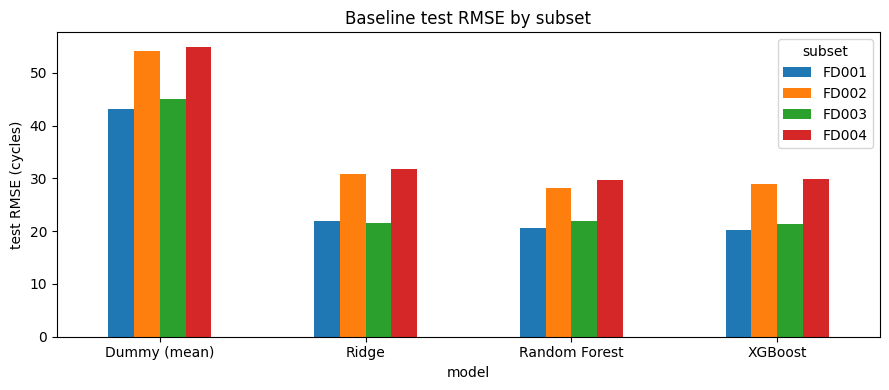

In [7]:
order = list(MODELS.keys())
print('Test RMSE'); display(res.pivot(index='model', columns='subset', values='test_rmse').loc[order])
print('NASA score'); display(res.pivot(index='model', columns='subset', values='nasa_score').loc[order])
print('Validation RMSE (held-out engines)'); display(res.pivot(index='model', columns='subset', values='val_rmse').loc[order])

res.pivot(index='model', columns='subset', values='test_rmse').loc[order].plot.bar(figsize=(9, 4))
plt.ylabel('test RMSE (cycles)'); plt.title('Baseline test RMSE by subset'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 8. Sliding windows for the sequence models
Deep sequence models (LSTM/GRU/CNN) in Notebook 4 take a window of the last 30 cycles as one input. Every training cycle becomes one window (early cycles are padded by repeating the engine's first row); for each test engine only the final window is used.
Normalisation statistics, the feature lists and the windows are saved to Drive for the next notebooks.

In [8]:
WIN_LEN = 30

def make_windows(df, feats, win=WIN_LEN, last_only=False, target='RUL_clipped'):
    X, y, units = [], [], []
    for u, e in df.groupby('unit'):
        arr = e[feats].values.astype('float32')
        arr = np.pad(arr, ((win - 1, 0), (0, 0)), mode='edge')   # pad the start with the first row
        n = len(e)
        for i in ([n - 1] if last_only else range(n)):
            X.append(arr[i:i + win])
            units.append(u)
            if target is not None:
                y.append(e[target].values[i])
    y = np.array(y, dtype='float32') if target is not None else None
    return np.stack(X), y, np.array(units)

for fd in SUBSETS:
    X_tr, y_tr, u_tr = make_windows(train_n[fd], FEATS[fd])
    X_te, _, u_te = make_windows(test_n[fd], FEATS[fd], last_only=True, target=None)
    np.savez_compressed(f'{PROC_DIR}/windows_{fd}.npz',
                        X_train=X_tr, y_train=y_tr, units_train=u_tr,
                        X_test=X_te, units_test=u_te, y_test_true=rul_true[fd])
    SCALERS[fd][0].to_csv(f'{PROC_DIR}/scaler_{fd}_mean.csv')
    SCALERS[fd][1].to_csv(f'{PROC_DIR}/scaler_{fd}_std.csv')
    print(fd, 'train windows', X_tr.shape, '| test windows', X_te.shape)

with open(f'{PROC_DIR}/features.json', 'w') as f:
    json.dump(FEATS, f)

FD001 train windows (20631, 30, 14) | test windows (100, 30, 14)
FD002 train windows (53759, 30, 14) | test windows (259, 30, 14)
FD003 train windows (24720, 30, 15) | test windows (100, 30, 15)
FD004 train windows (61249, 30, 15) | test windows (248, 30, 15)


## 9. Key Findings

- **Sensor selection:** FD001 and FD002 retain 14 informative sensors, while FD003 and FD004 retain 15 sensors out of the original 21.

- **Normalisation:** Per-condition standardisation successfully brings training sensor values to approximately zero mean and unit standard deviation.

- **Rolling features:** A 10-cycle rolling window generates mean and standard deviation features, resulting in 42 features for FD001/FD002 and 45 for FD003/FD004.

- **Data leakage prevention:** Scaling statistics are fitted only on training data and applied unchanged to test data. Validation is also performed by splitting engines rather than individual rows.

- **Baseline comparison:** All three machine learning models (Ridge, Random Forest and XGBoost) perform considerably better than the Dummy Regressor.

- **Best validation performance:** XGBoost achieves the lowest validation RMSE across all four subsets, making it a strong baseline candidate.

- **Test performance:** XGBoost achieves the lowest test RMSE on FD001 (20.15) and FD003 (21.41), while Random Forest performs best on FD002 (28.17) and FD004 (29.64).

- **NASA score:** Random Forest performs best on FD002 (10512.00) and FD004 (7242.79), whereas XGBoost performs best on FD001 (1470.77) and Ridge on FD003 (1476.63).

- **Sequence preparation:** Generated 30-cycle sliding windows for training and one final window per test engine, with early cycles padded using the first available observation.

- **Saved outputs:** Normalisation statistics, selected sensor lists, baseline results and sequence windows are saved to Google Drive for subsequent modelling.

- **Next step:** Use the prepared sequence datasets to train deep learning architectures such as LSTM, GRU and CNN, and compare their performance against the established baselines.